### bipedal walker test



In [1]:
from google.colab import drive
drive.mount('/content/drive')

# %cd /content/drive/MyDrive
# !git clone https://github.com/openai/spinningup.git

#pip 설치
!pip install mpi4py
!pip install box2d
!pip install gymnasium[mujoco]

#py파일 참조를 위한 위치 변경
import sys
sys.path.append('/content/drive/MyDrive/Project/hanium/bipedalwalker')

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 73.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 99.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.0/42.0 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.7/6.7 MB 84.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 243.5/243.5 kB 24.3 MB/s eta 0:00:00


In [2]:
from sac import core
from utils.logx import EpochLogger
from utils.mpi_pytorch import setup_pytorch_for_mpi, sync_params, mpi_avg_grads
from utils.mpi_tools import mpi_fork, mpi_avg, proc_id, mpi_statistics_scalar, num_procs
from utils.run_utils import setup_logger_kwargs

from copy import deepcopy
import gym
import math
import pygame
import random
import time
import os
import math
import argparse
import itertools
import numpy as np
if not hasattr(np, 'bool8'):
    np.bool8 = np.bool_

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import Adam
import torch.nn.functional as F

import matplotlib
import matplotlib.pyplot as plt

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/pygame/pkgdata.py:25: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import resource_stream, resource_exists
/usr/local/lib/python3.12/dist-packages/pkg_resources/__init__.py:3154: De

In [ ]:
import gym
print(gym.__version__)

0.25.2


In [3]:
# 그래프 작성을 위한 지표 값 리스트 저장

# 기존 버전

baseline_epoch_rewards = []        # AverageEpRet (train)
baseline_test_rewards = []         # AverageTestEpRet


baseline_q1_vals = []              # AverageQ1Vals
baseline_q2_vals = []              # AverageQ2Vals
baseline_qtarget_vals = []         # AverageQTarget

baseline_std_q1_vals = []          # StdQ1Vals
baseline_std_q2_vals = []          # StdQ2Vals
baseline_std_qtarget_vals = []     # StdQTarget

baseline_q_gap_vals = []           # Q1 - Q2 차이 (안정성 체크)


# Reward Scaling 적용 버전

scaled_epoch_rewards = []
scaled_test_rewards = []


scaled_q1_vals = []
scaled_q2_vals = []
scaled_qtarget_vals = []

scaled_std_q1_vals = []
scaled_std_q2_vals = []
scaled_std_qtarget_vals = []

scaled_q_gap_vals = []


#### 기존 SpinningUP code기반

In [4]:
class ReplayBuffer:
    """
    A simple FIFO experience replay buffer for SAC agents.
    """

    def __init__(self, obs_dim, act_dim, size):
        self.obs_buf = np.zeros(core.combined_shape(size, obs_dim), dtype=np.float32)
        self.obs2_buf = np.zeros(core.combined_shape(size, obs_dim), dtype=np.float32)
        self.act_buf = np.zeros(core.combined_shape(size, act_dim), dtype=np.float32)
        self.rew_buf = np.zeros(size, dtype=np.float32)
        self.done_buf = np.zeros(size, dtype=np.float32)
        self.ptr, self.size, self.max_size = 0, 0, size

    def store(self, obs, act, rew, next_obs, done):
        self.obs_buf[self.ptr] = obs
        self.obs2_buf[self.ptr] = next_obs
        self.act_buf[self.ptr] = act
        self.rew_buf[self.ptr] = rew
        self.done_buf[self.ptr] = done
        self.ptr = (self.ptr+1) % self.max_size
        self.size = min(self.size+1, self.max_size)

    def sample_batch(self, batch_size=32):
        idxs = np.random.randint(0, self.size, size=batch_size)
        batch = dict(obs=self.obs_buf[idxs],
                     obs2=self.obs2_buf[idxs],
                     act=self.act_buf[idxs],
                     rew=self.rew_buf[idxs],
                     done=self.done_buf[idxs])
        return {k: torch.as_tensor(v, dtype=torch.float32) for k,v in batch.items()}



def sac(env_fn, actor_critic=core.MLPActorCritic, ac_kwargs=dict(), seed=0,
        steps_per_epoch=4000, epochs=100, replay_size=int(1e6), gamma=0.99,
        polyak=0.995, lr=1e-3, alpha=0.2, batch_size=256, start_steps=10000,
        update_after=1000, update_every=64, num_test_episodes=10, max_ep_len=1000,
        logger_kwargs=dict(), save_freq=1): #utd_ratio 추가

    logger = EpochLogger(**logger_kwargs)
    logger.save_config(locals())

    torch.manual_seed(seed)
    np.random.seed(seed)

    env, test_env = env_fn(), env_fn()
    obs_dim = env.observation_space.shape
    act_dim = env.action_space.shape[0]

    # Action limit for clamping: critically, assumes all dimensions share the same bound!
    act_limit = env.action_space.high[0]

    # Create actor-critic module and target networks
    ac = actor_critic(env.observation_space, env.action_space, **ac_kwargs)
    ac_targ = deepcopy(ac)

    # Freeze target networks with respect to optimizers (only update via polyak averaging)
    for p in ac_targ.parameters():
        p.requires_grad = False

    # List of parameters for both Q-networks (save this for convenience)
    q_params = itertools.chain(ac.q1.parameters(), ac.q2.parameters())

    # Experience buffer
    replay_buffer = ReplayBuffer(obs_dim=obs_dim, act_dim=act_dim, size=replay_size)

    # Count variables (protip: try to get a feel for how different size networks behave!)
    var_counts = tuple(core.count_vars(module) for module in [ac.pi, ac.q1, ac.q2])
    logger.log('\nNumber of parameters: \t pi: %d, \t q1: %d, \t q2: %d\n'%var_counts)

    # Set up function for computing SAC Q-losses
    def compute_loss_q(data):
        o, a, r, o2, d = data['obs'], data['act'], data['rew'], data['obs2'], data['done']

        q1 = ac.q1(o,a)
        q2 = ac.q2(o,a)

        # Bellman backup for Q functions
        with torch.no_grad():
            # Target actions come from *current* policy
            a2, logp_a2 = ac.pi(o2)

            # Target Q-values
            q1_pi_targ = ac_targ.q1(o2, a2)
            q2_pi_targ = ac_targ.q2(o2, a2)
            q_pi_targ = torch.min(q1_pi_targ, q2_pi_targ)
            backup = r + gamma * (1 - d) * (q_pi_targ - alpha * logp_a2)

        # MSE loss against Bellman backup
        loss_q1 = ((q1 - backup)**2).mean()
        loss_q2 = ((q2 - backup)**2).mean()
        loss_q = loss_q1 + loss_q2

        # Useful info for logging
        q_info = dict(Q1Vals=q1.detach().numpy(),
                      Q2Vals=q2.detach().numpy())

        return loss_q, q_info

    # Set up function for computing SAC pi loss
    def compute_loss_pi(data):
        o = data['obs']
        pi, logp_pi = ac.pi(o)
        q1_pi = ac.q1(o, pi)
        q2_pi = ac.q2(o, pi)
        q_pi = torch.min(q1_pi, q2_pi)

        # Entropy-regularized policy loss
        loss_pi = (alpha * logp_pi - q_pi).mean()

        # Useful info for logging
        pi_info = dict(LogPi=logp_pi.detach().numpy())

        return loss_pi, pi_info

    # Set up optimizers for policy and q-function
    pi_optimizer = Adam(ac.pi.parameters(), lr=lr)
    q_optimizer = Adam(q_params, lr=lr)

    # Set up model saving
    logger.setup_pytorch_saver(ac)

    def update(data):
        # First run one gradient descent step for Q1 and Q2
        q_optimizer.zero_grad()
        loss_q, q_info = compute_loss_q(data)
        loss_q.backward()
        q_optimizer.step()

        # Record things
        logger.store(LossQ=loss_q.item(), **q_info)

        # Freeze Q-networks so you don't waste computational effort
        # computing gradients for them during the policy learning step.
        for p in q_params:
            p.requires_grad = False

        # Next run one gradient descent step for pi.
        pi_optimizer.zero_grad()
        loss_pi, pi_info = compute_loss_pi(data)
        loss_pi.backward()
        pi_optimizer.step()

        # Unfreeze Q-networks so you can optimize it at next DDPG step.
        for p in q_params:
            p.requires_grad = True

        # Record things
        logger.store(LossPi=loss_pi.item(), **pi_info)

        # Finally, update target networks by polyak averaging.
        with torch.no_grad():
            for p, p_targ in zip(ac.parameters(), ac_targ.parameters()):
                # NB: We use an in-place operations "mul_", "add_" to update target
                # params, as opposed to "mul" and "add", which would make new tensors.
                p_targ.data.mul_(polyak)
                p_targ.data.add_((1 - polyak) * p.data)

    def get_action(o, deterministic=False):
        return ac.act(torch.as_tensor(o, dtype=torch.float32),
                      deterministic)

    def test_agent():
        for j in range(num_test_episodes):
            o, d, ep_ret, ep_len = test_env.reset(), False, 0, 0
            while not(d or (ep_len == max_ep_len)):
                # Take deterministic actions at test time
                o, r, d, _ = test_env.step(get_action(o, True))
                ep_ret += r
                ep_len += 1
            logger.store(TestEpRet=ep_ret, TestEpLen=ep_len)

    def safe_get(logger, key, default=(0,0,0,0)):
        try:
            return logger.get_stats(key)
        except KeyError:
            return default

    # Prepare for interaction with environment
    total_steps = steps_per_epoch * epochs
    start_time = time.time()
    o, ep_ret, ep_len = env.reset(), 0, 0

    # Main loop: collect experience in env and update/log each epoch
    for t in range(total_steps):

        # Until start_steps have elapsed, randomly sample actions
        # from a uniform distribution for better exploration. Afterwards,
        # use the learned policy.
        if t > start_steps:
            a = get_action(o)
        else:
            a = env.action_space.sample()

        # Step the env
        o2, r, d, _ = env.step(a)
        ep_ret += r
        ep_len += 1

        # Ignore the "done" signal if it comes from hitting the time
        # horizon (that is, when it's an artificial terminal signal
        # that isn't based on the agent's state)
        d = False if ep_len==max_ep_len else d

        # Store experience to replay buffer
        replay_buffer.store(o, a, r, o2, d)

        # Super critical, easy to overlook step: make sure to update
        # most recent observation!
        o = o2

        # End of trajectory handling
        if d or (ep_len == max_ep_len):
            logger.store(EpRet=ep_ret, EpLen=ep_len)
            o, ep_ret, ep_len = env.reset(), 0, 0

        # Update handling
        if t >= update_after and t % update_every == 0:
            for j in range(update_every):
                batch = replay_buffer.sample_batch(batch_size)
                update(data=batch)

        # End of epoch handling
        if (t+1) % steps_per_epoch == 0:
            epoch = (t+1) // steps_per_epoch

            # Save model
            if (epoch % save_freq == 0) or (epoch == epochs):
                logger.save_state({'env': env}, None)

            # Test the performance of the deterministic version of the agent.
            test_agent()

            epoch_rewards = logger.get_stats('EpRet')[0]         # 평균 reward
            test_rewards = logger.get_stats('TestEpRet')[0]

            q1_mean = logger.get_stats('Q1Vals')[0]
            q1_std = logger.get_stats('Q1Vals')[1]
            q2_mean = logger.get_stats('Q2Vals')[0]
            q2_std = logger.get_stats('Q1Vals')[1]

            qtarget_mean, qtarget_std, _, _ = safe_get(logger, 'QTarget')


            # 리스트에 저장
            baseline_epoch_rewards.append(epoch_rewards)
            baseline_test_rewards.append(test_rewards)

            baseline_q1_vals.append(q1_mean)
            baseline_q2_vals.append(q2_mean)
            baseline_qtarget_vals.append(qtarget_mean)

            baseline_std_q1_vals.append(q1_std)
            baseline_std_q2_vals.append(q2_std)
            baseline_std_qtarget_vals.append(qtarget_std)

            baseline_q_gap_vals.append(abs(q1_mean - q2_mean))

            # Log info about epoch
            logger.log_tabular('Epoch', epoch)
            logger.log_tabular('EpRet', with_min_and_max=True)
            logger.log_tabular('TestEpRet', with_min_and_max=True)
            logger.log_tabular('EpLen', average_only=True)
            logger.log_tabular('TestEpLen', average_only=True)
            logger.log_tabular('TotalEnvInteracts', t)
            logger.log_tabular('Q1Vals', with_min_and_max=True)
            logger.log_tabular('Q2Vals', with_min_and_max=True)
            logger.log_tabular('LogPi', with_min_and_max=True)
            logger.log_tabular('LossPi', average_only=True)
            logger.log_tabular('LossQ', average_only=True)
            logger.log_tabular('Time', time.time()-start_time)
            logger.dump_tabular()

if __name__ == '__main__':
    import argparse
    parser = argparse.ArgumentParser()
    parser.add_argument('--env', type=str, default='Ant-v4')
    parser.add_argument('--hid', type=int, default=256)
    parser.add_argument('--l', type=int, default=2)
    parser.add_argument('--gamma', type=float, default=0.98)
    parser.add_argument('--seed', '-s', type=int, default=0)
    parser.add_argument('--epochs', type=int, default=20)
    parser.add_argument('--exp_name', type=str, default='sac')
    args, _ = parser.parse_known_args()

    from utils.run_utils import setup_logger_kwargs
    logger_kwargs = setup_logger_kwargs(args.exp_name, args.seed)

    torch.set_num_threads(torch.get_num_threads())

    sac(lambda : gym.make(args.env), actor_critic=core.MLPActorCritic,
        ac_kwargs=dict(hidden_sizes=[args.hid]*args.l),
        gamma=args.gamma, seed=args.seed, epochs=args.epochs,
        logger_kwargs=logger_kwargs)

Logging data to /content/drive/MyDrive/Project/hanium/bipedalwalker/data/sac/sac_s0/progress.txt
Saving config:

{
    "ac_kwargs":	{
        "hidden_sizes":	[
            256,
            256
        ]
    },
    "actor_critic":	"MLPActorCritic",
    "alpha":	0.2,
    "batch_size":	256,
    "env_fn":	"<function <lambda> at 0x7faa8e320360>",
    "epochs":	20,
    "exp_name":	"sac",
    "gamma":	0.98,
    "logger":	{
        "<utils.logx.EpochLogger object at 0x7faa904a7230>":	{
            "epoch_dict":	{},
            "exp_name":	"sac",
            "first_row":	true,
            "log_current_row":	{},
            "log_headers":	[],
            "output_dir":	"/content/drive/MyDrive/Project/hanium/bipedalwalker/data/sac/sac_s0",
            "output_file":	{
                "<_io.TextIOWrapper name='/content/drive/MyDrive/Project/hanium/bipedalwalker/data/sac/sac_s0/progress.txt' mode='w' encoding='utf-8'>":	{
                    "mode":	"w"
                }
            }
        }
    

/usr/local/lib/python3.12/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.12/dist-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(



Number of parameters: 	 pi: 77072, 	 q1: 75265, 	 q2: 75265

---------------------------------------
|             Epoch |               1 |
|      AverageEpRet |           -54.3 |
|          StdEpRet |            93.6 |
|          MaxEpRet |            22.1 |
|          MinEpRet |            -345 |
|  AverageTestEpRet |            23.5 |
|      StdTestEpRet |            97.6 |
|      MaxTestEpRet |             247 |
|      MinTestEpRet |           -83.8 |
|             EpLen |             178 |
|         TestEpLen |             260 |
| TotalEnvInteracts |           4e+03 |
|     AverageQ1Vals |            5.81 |
|         StdQ1Vals |            4.06 |
|         MaxQ1Vals |            28.9 |
|         MinQ1Vals |           -6.95 |
|     AverageQ2Vals |            5.81 |
|         StdQ2Vals |            4.06 |
|         MaxQ2Vals |            29.4 |
|         MinQ2Vals |           -6.63 |
|      AverageLogPi |           -3.99 |
|          StdLogPi |            1.87 |
|          MaxLogP

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------------
|             Epoch |               2 |
|      AverageEpRet |           -64.4 |
|          StdEpRet |            98.8 |
|          MaxEpRet |            7.29 |
|          MinEpRet |            -347 |
|  AverageTestEpRet |            -113 |
|      StdTestEpRet |             178 |
|      MaxTestEpRet |           -6.15 |
|      MinTestEpRet |            -484 |
|             EpLen |             172 |
|         TestEpLen |             232 |
| TotalEnvInteracts |           8e+03 |
|     AverageQ1Vals |            19.9 |
|         StdQ1Vals |            6.95 |
|         MaxQ1Vals |            61.8 |
|         MinQ1Vals |           -9.35 |
|     AverageQ2Vals |            19.9 |
|         StdQ2Vals |            6.95 |
|         MaxQ2Vals |            60.9 |
|         MinQ2Vals |           -6.26 |
|      AverageLogPi |           -1.65 |
|          StdLogPi |            2.77 |
|          MaxLogPi |              19 |
|          MinLogPi |           -15.9 |


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (32 outputs left out)

---------------------------------------
|             Epoch |              19 |
|      AverageEpRet |             127 |
|          StdEpRet |             114 |
|          MaxEpRet |             361 |
|          MinEpRet |            24.3 |
|  AverageTestEpRet |             879 |
|      StdTestEpRet |            80.3 |
|      MaxTestEpRet |             992 |
|      MinTestEpRet |             681 |
|             EpLen |             272 |
|         TestEpLen |           1e+03 |
| TotalEnvInteracts |         7.6e+04 |
|     AverageQ1Vals |            28.4 |
|         StdQ1Vals |            5.12 |
|         MaxQ1Vals |            59.5 |
|         MinQ1Vals |           -14.2 |
|     AverageQ2Vals |            28.4 |
|         StdQ2Vals |            5.12 |
|         MaxQ2Vals |            58.4 |
|         MinQ2Vals |           -16.5 |
|      AverageLogPi |           -2.83 |
|          StdLogPi |            1.91 |
|          MaxLogPi |            17.6 |
|          MinLogPi |           -16.6 |


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------------
|             Epoch |              20 |
|      AverageEpRet |             186 |
|          StdEpRet |             140 |
|          MaxEpRet |             404 |
|          MinEpRet |            10.6 |
|  AverageTestEpRet |             881 |
|      StdTestEpRet |            64.6 |
|      MaxTestEpRet |             963 |
|      MinTestEpRet |             774 |
|             EpLen |             495 |
|         TestEpLen |           1e+03 |
| TotalEnvInteracts |           8e+04 |
|     AverageQ1Vals |            29.1 |
|         StdQ1Vals |            5.14 |
|         MaxQ1Vals |            61.5 |
|         MinQ1Vals |           -17.6 |
|     AverageQ2Vals |            29.1 |
|         StdQ2Vals |            5.14 |
|         MaxQ2Vals |            60.7 |
|         MinQ2Vals |           -22.2 |
|      AverageLogPi |           -2.82 |
|          StdLogPi |            1.93 |
|          MaxLogPi |            18.3 |
|          MinLogPi |           -15.4 |


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


#### 변경된 Reward Cliping 기반

In [5]:
class ReplayBuffer:

    def __init__(self, obs_dim, act_dim, size):
        self.obs_buf = np.zeros(core.combined_shape(size, obs_dim), dtype=np.float32)
        self.obs2_buf = np.zeros(core.combined_shape(size, obs_dim), dtype=np.float32)
        self.act_buf = np.zeros(core.combined_shape(size, act_dim), dtype=np.float32)
        self.rew_buf = np.zeros(size, dtype=np.float32)
        self.done_buf = np.zeros(size, dtype=np.float32)
        self.ptr, self.size, self.max_size = 0, 0, size
        self.reward_history = []

    def store(self, obs, act, rew, next_obs, done):
        self.obs_buf[self.ptr] = obs
        self.obs2_buf[self.ptr] = next_obs
        self.act_buf[self.ptr] = act
        self.rew_buf[self.ptr] = rew
        self.done_buf[self.ptr] = done
        self.ptr = (self.ptr+1) % self.max_size
        self.size = min(self.size+1, self.max_size)
        self.reward_history.append(rew)
        if len(self.reward_history) > 1000:
            self.reward_history.pop(0)

    def sample_batch(self, batch_size=32):
        idxs = np.random.randint(0, self.size, size=batch_size)
        batch = dict(obs=self.obs_buf[idxs],
                     obs2=self.obs2_buf[idxs],
                     act=self.act_buf[idxs],
                     rew=self.rew_buf[idxs],
                     done=self.done_buf[idxs])
        return {k: torch.as_tensor(v, dtype=torch.float32) for k,v in batch.items()}



def sac(env_fn, actor_critic=core.MLPActorCritic, ac_kwargs=dict(), seed=0,
        steps_per_epoch=4000, epochs=100, replay_size=int(1e6), gamma=0.99,
        polyak=0.995, lr=1e-3, alpha=0.2, batch_size=256, start_steps=10000,
        update_after=1000, update_every=64, num_test_episodes=10, max_ep_len=1000,
        logger_kwargs=dict(), save_freq=1): #utd_ratio 추가

    logger = EpochLogger(**logger_kwargs)
    logger.save_config(locals())

    torch.manual_seed(seed)
    np.random.seed(seed)

    env, test_env = env_fn(), env_fn()
    obs_dim = env.observation_space.shape
    act_dim = env.action_space.shape[0]

    # Action limit for clamping: critically, assumes all dimensions share the same bound!
    act_limit = env.action_space.high[0]

    # Create actor-critic module and target networks
    ac = actor_critic(env.observation_space, env.action_space, **ac_kwargs)
    ac_targ = deepcopy(ac)

    # Freeze target networks with respect to optimizers (only update via polyak averaging)
    for p in ac_targ.parameters():
        p.requires_grad = False

    # List of parameters for both Q-networks (save this for convenience)
    q_params = itertools.chain(ac.q1.parameters(), ac.q2.parameters())

    # Experience buffer
    replay_buffer = ReplayBuffer(obs_dim=obs_dim, act_dim=act_dim, size=replay_size)

    # Count variables (protip: try to get a feel for how different size networks behave!)
    var_counts = tuple(core.count_vars(module) for module in [ac.pi, ac.q1, ac.q2])
    logger.log('\nNumber of parameters: \t pi: %d, \t q1: %d, \t q2: %d\n'%var_counts)

    def compute_reward_scaling(buffer):
      if len(buffer.reward_history) < 10:
          return 1.0  # 너무 적은 샘플이면 스케일링 하지 않음
      reward_std = np.std(buffer.reward_history)
      # 분산이 높을수록 작게 스케일 → 예: scaling factor = 1 / (1 + std)
      scale = 1.0 / (1 + math.log(1 + reward_std))
      return float(np.clip(scale, 0.3, 1.0))  # 너무 작아지지 않도록 하한 설정

    # Set up function for computing SAC Q-losses
    def compute_loss_q(data):
        o, a, r, o2, d = data['obs'], data['act'], data['rew'], data['obs2'], data['done']

        q1 = ac.q1(o,a)
        q2 = ac.q2(o,a)
        r_scale = compute_reward_scaling(replay_buffer)

        # Bellman backup for Q functions
        with torch.no_grad():
            # Target actions come from *current* policy
            a2, logp_a2 = ac.pi(o2)

            # Target Q-values
            q1_pi_targ = ac_targ.q1(o2, a2)
            q2_pi_targ = ac_targ.q2(o2, a2)
            q_pi_targ = torch.min(q1_pi_targ, q2_pi_targ)
            backup = (r * r_scale) + gamma * (1 - d) * (q_pi_targ - alpha * logp_a2)

        # MSE loss against Bellman backup
        loss_q1 = ((q1 - backup)**2).mean()
        loss_q2 = ((q2 - backup)**2).mean()
        loss_q = loss_q1 + loss_q2

        # Useful info for logging
        q_info = dict(Q1Vals=q1.detach().numpy(),
                      Q2Vals=q2.detach().numpy(),
                      RawReward=r.detach().numpy(),
                      ScaledReward=r_scale,
                      QTarget=backup.detach().numpy())

        return loss_q, q_info

    # Set up function for computing SAC pi loss
    def compute_loss_pi(data):
        o = data['obs']
        pi, logp_pi = ac.pi(o)
        q1_pi = ac.q1(o, pi)
        q2_pi = ac.q2(o, pi)
        q_pi = torch.min(q1_pi, q2_pi)

        # Entropy-regularized policy loss
        loss_pi = (alpha * logp_pi - q_pi).mean()

        # Useful info for logging
        pi_info = dict(LogPi=logp_pi.detach().numpy())

        return loss_pi, pi_info

    # Set up optimizers for policy and q-function
    pi_optimizer = Adam(ac.pi.parameters(), lr=lr)
    q_optimizer = Adam(q_params, lr=lr)

    # Set up model saving
    logger.setup_pytorch_saver(ac)

    def update(data):
        # First run one gradient descent step for Q1 and Q2
        q_optimizer.zero_grad()
        loss_q, q_info = compute_loss_q(data)
        loss_q.backward()
        q_optimizer.step()

        # Record things
        logger.store(LossQ=loss_q.item(), **q_info)

        # Freeze Q-networks so you don't waste computational effort
        # computing gradients for them during the policy learning step.
        for p in q_params:
            p.requires_grad = False

        # Next run one gradient descent step for pi.
        pi_optimizer.zero_grad()
        loss_pi, pi_info = compute_loss_pi(data)
        loss_pi.backward()
        pi_optimizer.step()

        # Unfreeze Q-networks so you can optimize it at next DDPG step.
        for p in q_params:
            p.requires_grad = True

        # Record things
        logger.store(LossPi=loss_pi.item(), **pi_info)

        # Finally, update target networks by polyak averaging.
        with torch.no_grad():
            for p, p_targ in zip(ac.parameters(), ac_targ.parameters()):
                # NB: We use an in-place operations "mul_", "add_" to update target
                # params, as opposed to "mul" and "add", which would make new tensors.
                p_targ.data.mul_(polyak)
                p_targ.data.add_((1 - polyak) * p.data)

    def get_action(o, deterministic=False):
        return ac.act(torch.as_tensor(o, dtype=torch.float32),
                      deterministic)

    def test_agent():
        for j in range(num_test_episodes):
            o, d, ep_ret, ep_len = test_env.reset(), False, 0, 0
            while not(d or (ep_len == max_ep_len)):
                # Take deterministic actions at test time
                o, r, d, _ = test_env.step(get_action(o, True))
                ep_ret += r
                ep_len += 1
            logger.store(TestEpRet=ep_ret, TestEpLen=ep_len)

    def safe_get(logger, key, default=(0,0,0,0)):
      try:
          return logger.get_stats(key)
      except KeyError:
          return default

    # Prepare for interaction with environment
    total_steps = steps_per_epoch * epochs
    start_time = time.time()
    o, ep_ret, ep_len = env.reset(), 0, 0

    # Main loop: collect experience in env and update/log each epoch
    for t in range(total_steps):

        # Until start_steps have elapsed, randomly sample actions
        # from a uniform distribution for better exploration. Afterwards,
        # use the learned policy.
        if t > start_steps:
            a = get_action(o)
        else:
            a = env.action_space.sample()

        # Step the env
        o2, r, d, truncated = env.step(a)
        ep_ret += r
        ep_len += 1

        # Ignore the "done" signal if it comes from hitting the time
        # horizon (that is, when it's an artificial terminal signal
        # that isn't based on the agent's state)
        d = False if ep_len==max_ep_len else d

        # Store experience to replay buffer
        replay_buffer.store(o, a, r, o2, d)

        # Super critical, easy to overlook step: make sure to update
        # most recent observation!
        o = o2

        # End of trajectory handling
        if d or (ep_len == max_ep_len):
            logger.store(EpRet=ep_ret, EpLen=ep_len)
            o, ep_ret, ep_len = env.reset(), 0, 0

        # Update handling
        if t >= update_after and t % update_every == 0:
            for j in range(update_every):
                #for _ in range(utd_ratio):  # UTD 비율만큼 업데이트 반복
                batch = replay_buffer.sample_batch(batch_size)
                update(data=batch)

        # End of epoch handling
        if (t+1) % steps_per_epoch == 0:
            epoch = (t+1) // steps_per_epoch

            # Save model
            if (epoch % save_freq == 0) or (epoch == epochs):
                logger.save_state({'env': env}, None)

            # Test the performance of the deterministic version of the agent.
            test_agent()

            ep_ret_mean = logger.get_stats('EpRet')[0]
            test_ret_mean = logger.get_stats('TestEpRet')[0]

            q1_mean = logger.get_stats('Q1Vals')[0]
            q1_std = logger.get_stats('Q1Vals')[1]
            q2_mean = logger.get_stats('Q2Vals')[0]
            q2_std = logger.get_stats('Q2Vals')[1]
            qtarget_mean, qtarget_std = safe_get(logger, 'QTarget')
            # 리스트에 저장
            scaled_epoch_rewards.append(ep_ret_mean)
            scaled_test_rewards.append(test_ret_mean)

            scaled_q1_vals.append(q1_mean)
            scaled_q2_vals.append(q2_mean)
            scaled_qtarget_vals.append(qtarget_mean)

            scaled_std_q1_vals.append(q1_std)
            scaled_std_q2_vals.append(q2_std)
            scaled_std_qtarget_vals.append(qtarget_std)

            scaled_q_gap_vals.append(abs(q1_mean - q2_mean))

            # Log info about epoch
            logger.log_tabular('Epoch', epoch)
            logger.log_tabular('EpRet', with_min_and_max=True)
            logger.log_tabular('TestEpRet', with_min_and_max=True)
            logger.log_tabular('EpLen', average_only=True)
            logger.log_tabular('TestEpLen', average_only=True)
            logger.log_tabular('TotalEnvInteracts', t)
            logger.log_tabular('Q1Vals', with_min_and_max=True)
            logger.log_tabular('Q2Vals', with_min_and_max=True)
            logger.log_tabular('LogPi', with_min_and_max=True)
            logger.log_tabular('LossPi', average_only=True)
            logger.log_tabular('LossQ', average_only=True)
            logger.log_tabular('Time', time.time()-start_time)
            logger.log_tabular('RawReward', with_min_and_max=True)
            logger.log_tabular('ScaledReward', with_min_and_max=True)
            logger.log_tabular('QTarget', with_min_and_max=True)
            logger.dump_tabular()

In [6]:
if __name__ == '__main__':
    import argparse
    parser = argparse.ArgumentParser()
    parser.add_argument('--env', type=str, default='Ant-v4')
    parser.add_argument('--hid', type=int, default=256)
    parser.add_argument('--l', type=int, default=2)
    parser.add_argument('--gamma', type=float, default=0.98)
    parser.add_argument('--seed', '-s', type=int, default=0)
    parser.add_argument('--epochs', type=int, default=20)
    parser.add_argument('--exp_name', type=str, default='sac')
    args, _ = parser.parse_known_args()

    from utils.run_utils import setup_logger_kwargs
    logger_kwargs = setup_logger_kwargs(args.exp_name, args.seed)

    torch.set_num_threads(torch.get_num_threads())

    sac(lambda : gym.make(args.env), actor_critic=core.MLPActorCritic,
        ac_kwargs=dict(hidden_sizes=[args.hid]*args.l),
        gamma=args.gamma, seed=args.seed, epochs=args.epochs,
        logger_kwargs=logger_kwargs)

Logging data to /content/drive/MyDrive/Project/hanium/bipedalwalker/data/sac/sac_s0/progress.txt
Saving config:

{
    "ac_kwargs":	{
        "hidden_sizes":	[
            256,
            256
        ]
    },
    "actor_critic":	"MLPActorCritic",
    "alpha":	0.2,
    "batch_size":	256,
    "env_fn":	"<function <lambda> at 0x7faa783bdbc0>",
    "epochs":	20,
    "exp_name":	"sac",
    "gamma":	0.98,
    "logger":	{
        "<utils.logx.EpochLogger object at 0x7fa8b6843c80>":	{
            "epoch_dict":	{},
            "exp_name":	"sac",
            "first_row":	true,
            "log_current_row":	{},
            "log_headers":	[],
            "output_dir":	"/content/drive/MyDrive/Project/hanium/bipedalwalker/data/sac/sac_s0",
            "output_file":	{
                "<_io.TextIOWrapper name='/content/drive/MyDrive/Project/hanium/bipedalwalker/data/sac/sac_s0/progress.txt' mode='w' encoding='utf-8'>":	{
                    "mode":	"w"
                }
            }
        }
    

/usr/local/lib/python3.12/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.12/dist-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(


-----------------------------------------
|               Epoch |               1 |
|        AverageEpRet |           -33.4 |
|            StdEpRet |              74 |
|            MaxEpRet |            27.3 |
|            MinEpRet |            -432 |
|    AverageTestEpRet |            26.6 |
|        StdTestEpRet |            45.8 |
|        MaxTestEpRet |             116 |
|        MinTestEpRet |           -36.3 |
|               EpLen |            99.1 |
|           TestEpLen |             530 |
|   TotalEnvInteracts |           4e+03 |
|       AverageQ1Vals |            6.16 |
|           StdQ1Vals |            3.98 |
|           MaxQ1Vals |            25.8 |
|           MinQ1Vals |           -4.01 |
|       AverageQ2Vals |            6.16 |
|           StdQ2Vals |            3.98 |
|           MaxQ2Vals |            25.8 |
|           MinQ2Vals |           -2.93 |
|        AverageLogPi |           -4.26 |
|            StdLogPi |            1.77 |
|            MaxLogPi |           

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
|               Epoch |               2 |
|        AverageEpRet |             -31 |
|            StdEpRet |            58.6 |
|            MaxEpRet |            31.6 |
|            MinEpRet |            -285 |
|    AverageTestEpRet |            -207 |
|        StdTestEpRet |             272 |
|        MaxTestEpRet |           -6.11 |
|        MinTestEpRet |            -630 |
|               EpLen |             110 |
|           TestEpLen |             333 |
|   TotalEnvInteracts |           8e+03 |
|       AverageQ1Vals |            22.4 |
|           StdQ1Vals |            7.91 |
|           MaxQ1Vals |              53 |
|           MinQ1Vals |           -5.87 |
|       AverageQ2Vals |            22.4 |
|           StdQ2Vals |            7.91 |
|           MaxQ2Vals |            54.2 |
|           MinQ2Vals |           -8.17 |
|        AverageLogPi |          -0.888 |
|            StdLogPi |            3.22 |
|            MaxLogPi |           

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (32 outputs left out)

-----------------------------------------
|               Epoch |              19 |
|        AverageEpRet |            62.2 |
|            StdEpRet |              66 |
|            MaxEpRet |             249 |
|            MinEpRet |           0.962 |
|    AverageTestEpRet |             735 |
|        StdTestEpRet |            98.6 |
|        MaxTestEpRet |             911 |
|        MinTestEpRet |             645 |
|               EpLen |             263 |
|           TestEpLen |           1e+03 |
|   TotalEnvInteracts |         7.6e+04 |
|       AverageQ1Vals |            28.5 |
|           StdQ1Vals |            4.31 |
|           MaxQ1Vals |            46.1 |
|           MinQ1Vals |           -15.6 |
|       AverageQ2Vals |            28.5 |
|           StdQ2Vals |            4.31 |
|           MaxQ2Vals |            50.8 |
|           MinQ2Vals |           -20.8 |
|        AverageLogPi |            -3.8 |
|            StdLogPi |            1.68 |
|            MaxLogPi |           

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
|               Epoch |              20 |
|        AverageEpRet |            71.4 |
|            StdEpRet |            56.9 |
|            MaxEpRet |             159 |
|            MinEpRet |           -2.17 |
|    AverageTestEpRet |             802 |
|        StdTestEpRet |            99.6 |
|        MaxTestEpRet |             969 |
|        MinTestEpRet |             701 |
|               EpLen |             445 |
|           TestEpLen |           1e+03 |
|   TotalEnvInteracts |           8e+04 |
|       AverageQ1Vals |            29.1 |
|           StdQ1Vals |            4.49 |
|           MaxQ1Vals |            45.6 |
|           MinQ1Vals |           -26.3 |
|       AverageQ2Vals |            29.1 |
|           StdQ2Vals |            4.48 |
|           MaxQ2Vals |            47.1 |
|           MinQ2Vals |           -15.2 |
|        AverageLogPi |           -3.78 |
|            StdLogPi |            1.67 |
|            MaxLogPi |           

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


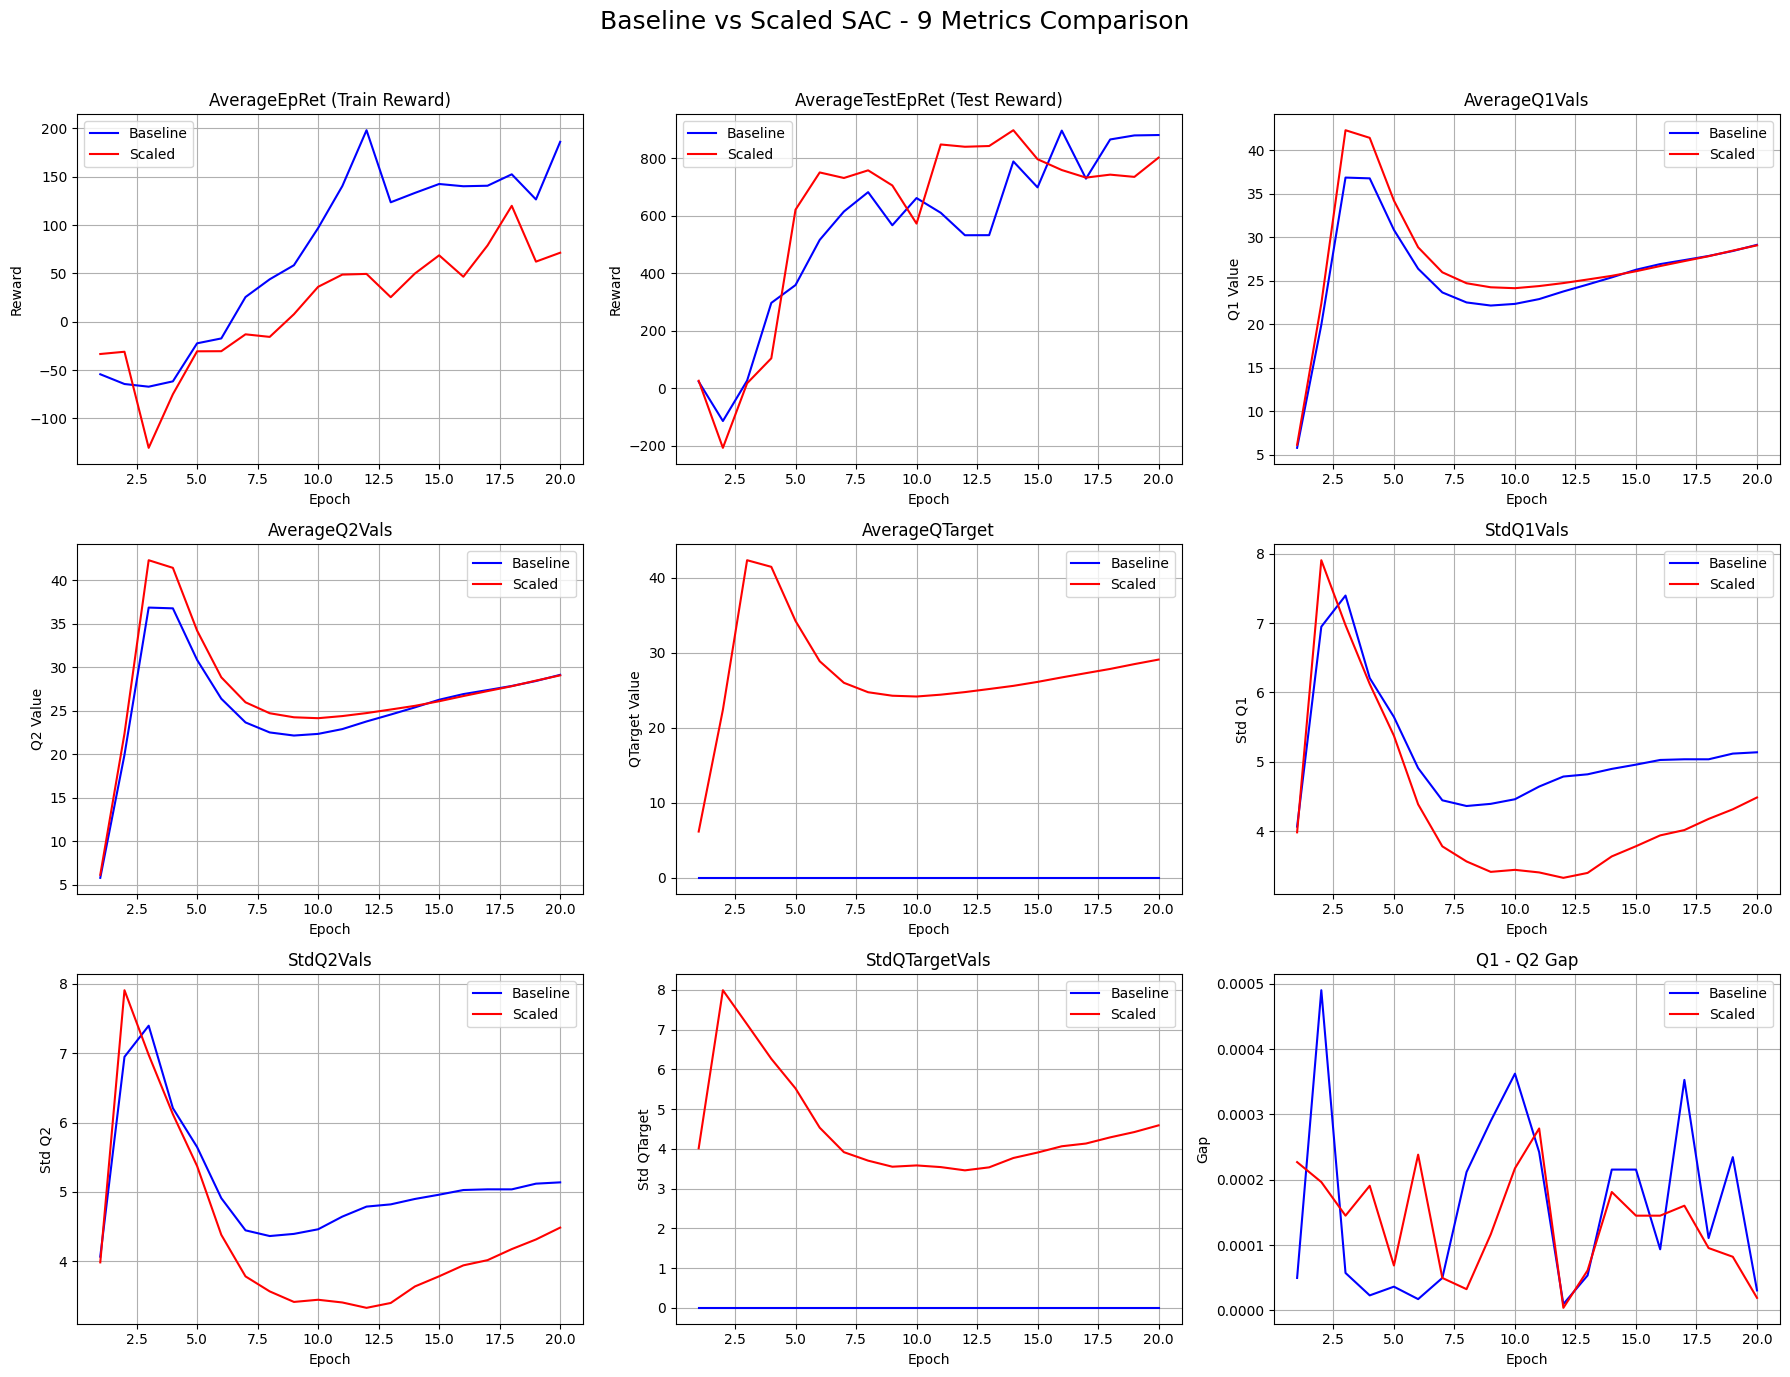

In [7]:
# import matplotlib.pyplot as plt
# import numpy as np

# X축 (epoch)
epochs = np.arange(1, len(baseline_epoch_rewards)+1)

# -------------------------------
# 지표 정의 (타이틀, baseline 리스트, scaled 리스트)
# -------------------------------
metrics = {
    "AverageEpRet (Train Reward)": (baseline_epoch_rewards, scaled_epoch_rewards, "Reward"),
    "AverageTestEpRet (Test Reward)": (baseline_test_rewards, scaled_test_rewards, "Reward"),
    "AverageQ1Vals": (baseline_q1_vals, scaled_q1_vals, "Q1 Value"),
    "AverageQ2Vals": (baseline_q2_vals, scaled_q2_vals, "Q2 Value"),
    "AverageQTarget": (baseline_qtarget_vals, scaled_qtarget_vals, "QTarget Value"),
    "StdQ1Vals": (baseline_std_q1_vals, scaled_std_q1_vals, "Std Q1"),
    "StdQ2Vals": (baseline_std_q2_vals, scaled_std_q2_vals, "Std Q2"),
    "StdQTargetVals": (baseline_std_qtarget_vals, scaled_std_qtarget_vals, "Std QTarget"),
    "Q1 - Q2 Gap": (baseline_q_gap_vals, scaled_q_gap_vals, "Gap"),
}

# -------------------------------
# 3x3 subplot 생성
# -------------------------------
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()  # 2D → 1D 배열로 변환해서 루프 돌리기

for i, (title, (baseline_vals, scaled_vals, ylabel)) in enumerate(metrics.items()):
    ax = axes[i]
    ax.plot(epochs, baseline_vals, label="Baseline", color="blue")
    ax.plot(epochs, scaled_vals, label="Scaled", color="red")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(True)

plt.suptitle("Baseline vs Scaled SAC - 9 Metrics Comparison", fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### optuna hyperparameter 최적화

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 395.9/395.9 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.0/247.0 kB 21.8 MB/s eta 0:00:00


In [ ]:
import importlib
import sac.sac
importlib.reload(sac.sac)

<module 'sac.sac' from '/content/drive/MyDrive/Project/hanium/bipedalwalker/sac/sac.py'>

In [ ]:
import optuna
from sac.sac import sac   # 학습 함수 직접 불러오기
import gym
from utils.run_utils import setup_logger_kwargs
from sac import core

def objective(trial):
    # Optuna 튜닝 대상
    gamma = trial.suggest_categorical("gamma", [0.95, 0.98, 0.99, 0.995])
    tau = trial.suggest_categorical("tau", [0.005, 0.01, 0.02])
    lr = trial.suggest_float("lr", 1e-4, 1e-3, log=True)
    batch_size = trial.suggest_categorical("batch_size", [64, 128, 256])
    alpha = trial.suggest_categorical("alpha", [0.1, 0.2])
    update_every = trial.suggest_categorical("update_every", [10, 50, 100])
    start_steps = trial.suggest_categorical("start_steps", [1000, 5000, 10000])
    hidden_sizes = trial.suggest_categorical("hidden_sizes", [[256, 256], [400, 300]])

    # 로거 설정 등
    from utils.logx import EpochLogger
    ac_kwargs = dict(hidden_sizes=hidden_sizes)
    logger_kwargs = setup_logger_kwargs(f"trial_{trial.number}", seed=0)

    # 환경 및 actor 생성
    env_fn = lambda: gym.make("BipedalWalker-v3")

    # ppo 실행
    result = sac(
        env_fn,
        actor_critic=core.MLPActorCritic,
        ac_kwargs=ac_kwargs,
        gamma=gamma,
        polyak=tau,
        lr=lr,
        alpha=alpha,
        batch_size=batch_size,
        start_steps=start_steps,
        update_every=update_every,
        logger_kwargs=logger_kwargs,
        seed=0,
        epochs=30,
        steps_per_epoch=4000,
    )


    # ppo 내부에서 마지막 reward 값을 반환하도록 해야 함
    return result  # 예: 평균 reward 등

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=10)

print("Best params:", study.best_params)

[I 2025-07-12 07:14:15,571] A new study created in memory with name: no-name-f3b565f4-4a4a-46f8-9584-a831bfb8bd9a
/usr/local/lib/python3.11/dist-packages/optuna/distributions.py:518: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains [256, 256] which is of type list.
  warnings.warn(message)
/usr/local/lib/python3.11/dist-packages/optuna/distributions.py:518: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains [400, 300] which is of type list.
  warnings.warn(message)
/usr/local/lib/python3.11/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.11/dist-packages/gym/wrappers/step_api_co

Logging data to /content/drive/MyDrive/Project/hanium/bipedalwalker/data/trial_0/trial_0_s0/progress.txt
Saving config:

{
    "ac_kwargs":	{
        "hidden_sizes":	[
            400,
            300
        ]
    },
    "actor_critic":	"MLPActorCritic",
    "alpha":	0.2,
    "batch_size":	256,
    "env_fn":	"<function objective.<locals>.<lambda> at 0x7b3252bc3060>",
    "epochs":	30,
    "exp_name":	"trial_0",
    "gamma":	0.99,
    "logger":	{
        "<utils.logx.EpochLogger object at 0x7b3252a52bd0>":	{
            "epoch_dict":	{},
            "exp_name":	"trial_0",
            "first_row":	true,
            "log_current_row":	{},
            "log_headers":	[],
            "output_dir":	"/content/drive/MyDrive/Project/hanium/bipedalwalker/data/trial_0/trial_0_s0",
            "output_file":	{
                "<_io.TextIOWrapper name='/content/drive/MyDrive/Project/hanium/bipedalwalker/data/trial_0/trial_0_s0/progress.txt' mode='w' encoding='utf-8'>":	{
                    "mode":

[W 2025-07-12 07:52:21,369] Trial 0 failed with parameters: {'gamma': 0.99, 'tau': 0.02, 'lr': 0.0008929773790088332, 'batch_size': 256, 'alpha': 0.2, 'update_every': 50, 'start_steps': 1000, 'hidden_sizes': [400, 300]} because of the following error: The value None could not be cast to float..
[W 2025-07-12 07:52:21,370] Trial 0 failed with value None.


/usr/local/lib/python3.11/dist-packages/optuna/distributions.py:518: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains [256, 256] which is of type list.
  warnings.warn(message)
/usr/local/lib/python3.11/dist-packages/optuna/distributions.py:518: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains [400, 300] which is of type list.
  warnings.warn(message)


Logging data to /content/drive/MyDrive/Project/hanium/bipedalwalker/data/trial_1/trial_1_s0/progress.txt
Saving config:

{
    "ac_kwargs":	{
        "hidden_sizes":	[
            256,
            256
        ]
    },
    "actor_critic":	"MLPActorCritic",
    "alpha":	0.2,
    "batch_size":	128,
    "env_fn":	"<function objective.<locals>.<lambda> at 0x7b3252a9ed40>",
    "epochs":	30,
    "exp_name":	"trial_1",
    "gamma":	0.95,
    "logger":	{
        "<utils.logx.EpochLogger object at 0x7b3252afbad0>":	{
            "epoch_dict":	{},
            "exp_name":	"trial_1",
            "first_row":	true,
            "log_current_row":	{},
            "log_headers":	[],
            "output_dir":	"/content/drive/MyDrive/Project/hanium/bipedalwalker/data/trial_1/trial_1_s0",
            "output_file":	{
                "<_io.TextIOWrapper name='/content/drive/MyDrive/Project/hanium/bipedalwalker/data/trial_1/trial_1_s0/progress.txt' mode='w' encoding='utf-8'>":	{
                    "mode":

/usr/local/lib/python3.11/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.11/dist-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(


... (31 outputs left out)

/usr/local/lib/python3.11/dist-packages/optuna/distributions.py:518: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains [256, 256] which is of type list.
  warnings.warn(message)
/usr/local/lib/python3.11/dist-packages/optuna/distributions.py:518: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains [400, 300] which is of type list.
  warnings.warn(message)


Logging data to /content/drive/MyDrive/Project/hanium/bipedalwalker/data/trial_8/trial_8_s0/progress.txt
Saving config:

{
    "ac_kwargs":	{
        "hidden_sizes":	[
            256,
            256
        ]
    },
    "actor_critic":	"MLPActorCritic",
    "alpha":	0.2,
    "batch_size":	256,
    "env_fn":	"<function objective.<locals>.<lambda> at 0x7b3252bc36a0>",
    "epochs":	30,
    "exp_name":	"trial_8",
    "gamma":	0.99,
    "logger":	{
        "<utils.logx.EpochLogger object at 0x7b325014f390>":	{
            "epoch_dict":	{},
            "exp_name":	"trial_8",
            "first_row":	true,
            "log_current_row":	{},
            "log_headers":	[],
            "output_dir":	"/content/drive/MyDrive/Project/hanium/bipedalwalker/data/trial_8/trial_8_s0",
            "output_file":	{
                "<_io.TextIOWrapper name='/content/drive/MyDrive/Project/hanium/bipedalwalker/data/trial_8/trial_8_s0/progress.txt' mode='w' encoding='utf-8'>":	{
                    "mode":

/usr/local/lib/python3.11/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.11/dist-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(



Number of parameters: 	 pi: 74248, 	 q1: 73473, 	 q2: 73473

---------------------------------------
|             Epoch |               1 |
|      AverageEpRet |           -98.9 |
|          StdEpRet |            16.8 |
|          MaxEpRet |           -59.2 |
|          MinEpRet |            -119 |
|  AverageTestEpRet |            -111 |
|      StdTestEpRet |           0.611 |
|      MaxTestEpRet |            -110 |
|      MinTestEpRet |            -111 |
|             EpLen |             263 |
|         TestEpLen |            49.5 |
| TotalEnvInteracts |           4e+03 |
|     AverageQ1Vals |             125 |
|         StdQ1Vals |             277 |
|         MaxQ1Vals |        1.99e+03 |
|         MinQ1Vals |            -206 |
|     AverageQ2Vals |             125 |
|         StdQ2Vals |             277 |
|         MaxQ2Vals |        1.99e+03 |
|         MinQ2Vals |            -196 |
|      AverageLogPi |          -0.498 |
|          StdLogPi |            3.14 |
|          MaxLogP